# Publication post-processing — Test Case 3

Python/Jupyter conversion of `POST_TC3_SPP_PUBLICATION_2x3.m`, styled with the frozen KAPI-ELM publication template. Run Stage 1 and Stage 2 first. The notebook creates publication-ready PDF/PNG figures and `TC3_SPP_Table.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from kapi_onet_publication_style import (
    DOUBLE_COLUMN_WIDTH,
    BLACK, BLUE, VERMILLION,
    apply_publication_style,
    add_major_y_grid,
    save_figure,
)

apply_publication_style()

f1 = Path('STAGE_01_INF_RBF_SPP_attention_PAPER.npz')
f2 = Path('STAGE_02_INF_RBF_SPP_results_PAPER.npz')
if not f1.exists():
    raise FileNotFoundError(f'Missing {f1}. Run Stage 1 first.')
if not f2.exists():
    raise FileNotFoundError(f'Missing {f2}. Run Stage 2 first.')

P = np.load(f1)
C = np.load(f2)

def s(D, name, cast=float):
    return cast(D[name].item())

tol = 1e-14
if abs(s(P, 'nu') - s(C, 'nu')) > tol:
    raise ValueError('Predictor/corrector nu mismatch.')
if abs(s(P, 'sigma_x') - s(C, 'sigma_x')) > tol:
    raise ValueError('Predictor/corrector kernel-scale mismatch.')
if s(P, 'NBx', int) != s(C, 'NBx', int):
    raise ValueError('Predictor/corrector attention-block mismatch.')

## Standardized 2×3 publication figure

The figure uses the shared frozen style at final double-column width. In keeping with the template, panel-letter labels are omitted; descriptive titles retain the six panel semantics.

Saved: TC3_SPP_2x3.pdf, TC3_SPP_2x3.png


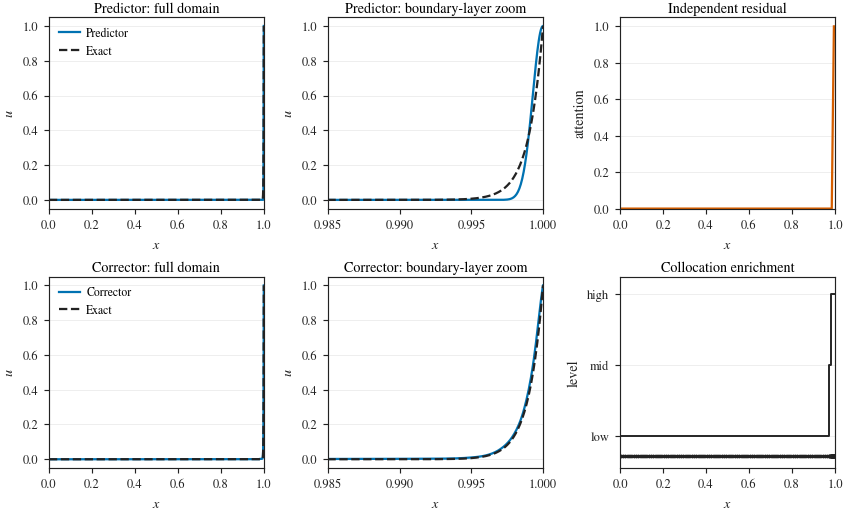

In [2]:
XL, XR, nu = s(P, 'XL'), s(P, 'XR'), s(P, 'nu')
x_zoom_L = max(XL, XR - 15 * nu)
x = P['x_plot']
x_edges = P['x_edges']
x_cent = 0.5 * (x_edges[:-1] + x_edges[1:])
level_map = P['level_map']

# Final-size double-column figure.
fig, ax = plt.subplots(
    2, 3,
    figsize=(DOUBLE_COLUMN_WIDTH, 0.61 * DOUBLE_COLUMN_WIDTH),
    constrained_layout=True,
)

# Predictor — full domain
ax[0, 0].plot(x, P['u_pred'], color=BLUE, label='Predictor')
ax[0, 0].plot(x, P['u_ex'], color=BLACK, ls='--', label='Exact')
ax[0, 0].set(xlim=(XL, XR), ylim=(-0.05, 1.05), xlabel=r'$x$', ylabel=r'$u$',
             title='Predictor: full domain')
add_major_y_grid(ax[0, 0])
ax[0, 0].legend(loc='upper left')

# Predictor — boundary-layer zoom
ax[0, 1].plot(x, P['u_pred'], color=BLUE)
ax[0, 1].plot(x, P['u_ex'], color=BLACK, ls='--')
ax[0, 1].set(xlim=(x_zoom_L, XR), ylim=(-0.05, 1.05), xlabel=r'$x$', ylabel=r'$u$',
             title='Predictor: boundary-layer zoom')
add_major_y_grid(ax[0, 1])

# Independent residual attention
ax[0, 2].plot(x_cent, P['attention_score'], color=VERMILLION)
ax[0, 2].set(xlim=(XL, XR), ylim=(0, 1.05), xlabel=r'$x$', ylabel='attention',
             title='Independent residual')
add_major_y_grid(ax[0, 2])

# Corrector — full domain
ax[1, 0].plot(x, C['u_adapt'], color=BLUE, label='Corrector')
ax[1, 0].plot(x, C['u_ex'], color=BLACK, ls='--', label='Exact')
ax[1, 0].set(xlim=(XL, XR), ylim=(-0.05, 1.05), xlabel=r'$x$', ylabel=r'$u$',
             title='Corrector: full domain')
add_major_y_grid(ax[1, 0])
ax[1, 0].legend(loc='upper left')

# Corrector — boundary-layer zoom
ax[1, 1].plot(x, C['u_adapt'], color=BLUE)
ax[1, 1].plot(x, C['u_ex'], color=BLACK, ls='--')
ax[1, 1].set(xlim=(x_zoom_L, XR), ylim=(-0.05, 1.05), xlabel=r'$x$', ylabel=r'$u$',
             title='Corrector: boundary-layer zoom')
add_major_y_grid(ax[1, 1])

# Collocation enrichment
ax[1, 2].step(
    x_edges, np.r_[level_map, level_map[-1]],
    where='post', color=BLACK, lw=1.15,
)
ax[1, 2].plot(
    C['xP_adapt'], 0.72 * np.ones_like(C['xP_adapt']),
    '.', color=BLACK, ms=2.2,
)
ax[1, 2].set(
    xlim=(XL, XR), ylim=(0.55, 3.25), xlabel=r'$x$', ylabel='level',
    title='Collocation enrichment',
)
ax[1, 2].set_yticks([1, 2, 3], ['low', 'mid', 'high'])
add_major_y_grid(ax[1, 2])

saved = save_figure(fig, 'TC3_SPP_2x3', formats=('pdf', 'png'), png_dpi=600)
print('Saved:', ', '.join(str(p) for p in saved))
plt.show()

## Joint-table CSV row

In [3]:
row = {
    'Case': 'Singular perturbation',
    'Equation': 'u_x - nu u_xx = 0',
    'Parameter': f"nu={s(P,'nu'):.0e}",
    'Predictor_PDE': s(P,'Npde',int),
    'Predictor_RMSE': s(P,'rmse_predictor'),
    'Predictor_MaxError': s(P,'maxerr_predictor'),
    'Corrector_AvgPDE': s(C,'Np_adapt',int),
    'Corrector_MinPDE': s(C,'Np_adapt',int),
    'Corrector_MaxPDE': s(C,'Np_adapt',int),
    'Corrector_RMSE': s(C,'rmse_adaptive'),
    'Corrector_MaxError': s(C,'maxerr_adaptive'),
    'RMSE_Improvement': s(C,'rmse_gain_vs_predictor'),
    'MaxError_Improvement': s(C,'maxerr_gain_vs_predictor'),
    'Uniform_PDE': s(C,'Np_uniform',int),
    'Uniform_RMSE': s(C,'rmse_uniform'),
    'Uniform_MaxError': s(C,'maxerr_uniform'),
    'Adaptive_vs_Uniform_RMSE_Gain': s(C,'rmse_gain_vs_uniform'),
    'Adaptive_vs_Uniform_MaxError_Gain': s(C,'maxerr_gain_vs_uniform'),
    'Sigma_x': s(P,'sigma_x'),
    'Sigma_t': np.nan,
    'Pilot_PointsPerBlock': s(P,'Npde_per_block_pilot',int),
    'Low_PointsPerBlock': int(C['Npde_level'][0]),
    'Mid_PointsPerBlock': int(C['Npde_level'][1]),
    'High_PointsPerBlock': int(C['Npde_level'][2]),
    'Adaptive_Fraction_Full_Percent': s(C,'adaptive_fraction_full'),
    'Adaptive_Effective_Condition': s(C,'solA_cond_eff'),
    'Uniform_Effective_Condition': s(C,'solU_cond_eff'),
}
T = pd.DataFrame([row])
T.to_csv('TC3_SPP_Table.csv', index=False)
display(T)

print('Publication outputs created:')
print('  TC3_SPP_2x3.png')
print('  TC3_SPP_2x3.eps')
print('  TC3_SPP_Table.csv')
print('\nTable summary:')
print(f"  Predictor RMSE         = {row['Predictor_RMSE']:.6e}")
print(f"  Corrector RMSE         = {row['Corrector_RMSE']:.6e}")
print(f"  Uniform RMSE           = {row['Uniform_RMSE']:.6e}")
print(f"  Adaptive PDE points    = {row['Corrector_AvgPDE']}")
print(f"  Uniform PDE points     = {row['Uniform_PDE']}")
print(f"  Gain vs predictor      = {row['RMSE_Improvement']:.3f} x")
print(f"  Gain vs uniform        = {row['Adaptive_vs_Uniform_RMSE_Gain']:.3f} x")

,Case,Equation,Parameter,Predictor_PDE,Predictor_RMSE,Predictor_MaxError,Corrector_AvgPDE,Corrector_MinPDE,Corrector_MaxPDE,Corrector_RMSE,...,Adaptive_vs_Uniform_MaxError_Gain,Sigma_x,Sigma_t,Pilot_PointsPerBlock,Low_PointsPerBlock,Mid_PointsPerBlock,High_PointsPerBlock,Adaptive_Fraction_Full_Percent,Adaptive_Effective_Condition,Uniform_Effective_Condition
0,Singular perturbation,u_x - nu u_xx = 0,nu=1e-03,200,0.005945,0.181699,250,250,250,0.00176,...,2.794623,0.0005,NaN,2,2,8,24,10.416667,536919.352502,111994.03947


Publication outputs created:
  TC3_SPP_2x3.png
  TC3_SPP_2x3.eps
  TC3_SPP_Table.csv

Table summary:
  Predictor RMSE         = 5.945489e-03
  Corrector RMSE         = 1.760180e-03
  Uniform RMSE           = 5.945950e-03
  Adaptive PDE points    = 250
  Uniform PDE points     = 250
  Gain vs predictor      = 3.378 x
  Gain vs uniform        = 3.378 x
